# Fashion-MNIST Image Classification

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Predict clothing categories from small grayscale images.

**Approach:** Convolutional neural networks with TensorFlow/Keras.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 1 Project 2 Fashion MNIST CNN </span>
    </span>
    </center>
<br>


## Classification with ( Deep Learning Technics)
### GUERBOUZ MOHAMMED ALAA EDDINE

In [1]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

#### **Explanation:**
- We import TensorFlow and Keras for building and training the deep learning model.
- Matplotlib is used for visualizing the images.
- NumPy is used for numerical operations on the dataset.s np

In [5]:
# Load the Fashion MNIST dataset
dataset = datasets.fashion_mnist.load_data()
(train_images, train_labels), (test_images, test_labels) = dataset
# Define class names for Fashion MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

The images in this dataset are 28 $\times$ 28 arrays, with pixel values in the range `[0, 255]`. The *labels* are an array of integers, in the range `[0, 9]`. These correspond to the *class* of clothing the image represents:

<table>
  <tr>
    <th>Label</th>
    <th>Class</th> 
  </tr>
  <tr>
    <td>0</td>
    <td>T-shirt/top</td> 
  </tr>
  <tr>
    <td>1</td>
    <td>Trouser</td> 
  </tr>
    <tr>
    <td>2</td>
    <td>Pullover</td> 
  </tr>
    <tr>
    <td>3</td>
    <td>Dress</td> 
  </tr>
    <tr>
    <td>4</td>
    <td>Coat</td> 
  </tr>
    <tr>
    <td>5</td>
    <td>Sandal</td> 
  </tr>
    <tr>
    <td>6</td>
    <td>Shirt</td> 
  </tr>
    <tr>
    <td>7</td>
    <td>Sneaker</td> 
  </tr>
    <tr>
    <td>8</td>
    <td>Bag</td> 
  </tr>
    <tr>
    <td>9</td>
    <td>Ankle boot</td> 
  </tr>
</table>

Each image is mapped to a single label. Since the *class names* are not included with the dataset, we create them here to use later when plotting the images:

#### **Explanation:**
- The Fashion MNIST dataset is loaded using TensorFlow's `keras.datasets.fashion_mnist`.
- The dataset is split into training and testing sets:
  - `train_images` and `train_labels` are used for training the model.
  - `test_images` and `test_labels` are used for evaluating the model.
- `class_names` is a list of the 10 categories of clothing in the dataset.

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)


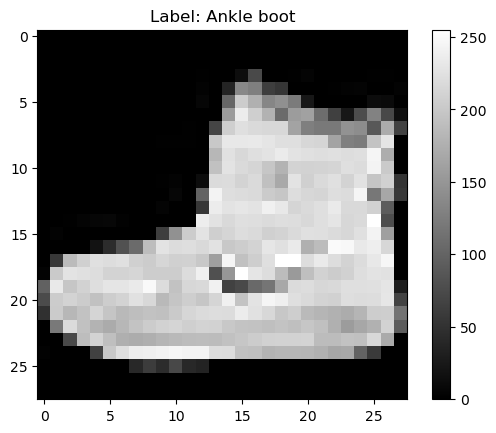

In [7]:
# Check the shape of the dataset
print("Training images shape:", train_images.shape)  # (60000, 28, 28)
print("Training labels shape:", train_labels.shape)  # (60000,)
print("Test images shape:", test_images.shape)       # (10000, 28, 28)
print("Test labels shape:", test_labels.shape)       # (10000,)

# Display the first image in the training set
plt.figure()
plt.imshow(train_images[0], cmap='gray')
plt.colorbar()
plt.title(f"Label: {class_names[train_labels[0]]}")
plt.show()

#### **Explanation:**
- We check the shape of the dataset to confirm that there are 60,000 training images and 10,000 test images, each of size 28x28 pixels.
- We visualize the first image in the training set using `matplotlib`. The image is displayed in grayscale, and the color bar shows the pixel intensity values (0 to 255).
- The title of the plot shows the corresponding label (e.g., "T-shirt/top").

In [55]:
# Normalize the pixel values to the range [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0

# Reshape the images to include a channel dimension (required for CNNs)
train_images = train_images.reshape((60000, 28, 28, 1))
test_images = test_images.reshape((10000, 28, 28, 1))


#### **Explanation:**
- The pixel values are normalized to the range `[0, 1]` by dividing by 255. This helps the model converge faster during training.
- The images are reshaped to include a channel dimension `(28, 28, 1)`, which is required for convolutional layers in the model.

In [41]:
# Define the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)), # First convolutional layer
    layers.MaxPooling2D((2, 2)),                                           # First max-pooling layer
    layers.Conv2D(64, (3, 3), activation='relu'),                          # Second convolutional layer
    layers.MaxPooling2D((2, 2)),                                           # Second max-pooling layer
    layers.Flatten(),                                                      # Flatten the output for dense layers
    layers.Dense(128, activation='relu'),                                  # Fully connected layer
    layers.Dense(10, activation='softmax')                                 # Output layer with softmax activation
])

# Print the model summary
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_6 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 flatten_2 (Flatten)         (None, 1600)              0         
                                                                 
 dense_4 (Dense)             (None, 128)              

#### **Explanation:**
- We build a **Convolutional Neural Network (CNN)** using Keras' `Sequential` API.
- The model consists of:
  - Two **convolutional layers** with ReLU activation to extract features from the images.
  - Two **max-pooling layers** to reduce the spatial dimensions and prevent overfitting.
  - A **flatten layer** to convert the 2D feature maps into a 1D vector.
  - A **fully connected (dense) layer** with 128 neurons and ReLU activation.
  - An **output layer** with 10 neurons (one for each class) and softmax activation to output class probabilities.
- The `model.summary()` function provides a detailed overview of the model's architecture.

In [42]:
# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

#### **Explanation:**
- The model is compiled using the Adam optimizer, which is efficient and requires less tuning.
- The loss function is set to `sparse_categorical_crossentropy`, which is suitable for multi-class classification with integer labels.
- The metric `accuracy` is used to evaluate the model's performance during training and testing.

In [43]:
# Train the model
history = model.fit(train_images, train_labels, epochs=10, 
                    validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 [==============================] - 17s 9ms/step - loss: 0.4380 - accuracy: 0.8411 - val_loss: 0.3342 - val_accuracy: 0.8766
Epoch 2/10
1875/1875 [==============================] - 15s 8ms/step - loss: 0.2957 - accuracy: 0.8896 - val_loss: 0.3193 - val_accuracy: 0.8799
Epoch 3/10
1875/1875 [==============================] - 16s 8ms/step - loss: 0.2506 - accuracy: 0.9074 - val_loss: 0.2955 - val_accuracy: 0.8877
Epoch 4/10
1875/1875 [==============================] - 16s 9ms/step - loss: 0.2196 - accuracy: 0.9183 - val_loss: 0.2583 - val_accuracy: 0.9042
Epoch 5/10
1875/1875 [==============================] - 16s 8ms/step - loss: 0.1930 - accuracy: 0.9285 - val_loss: 0.2617 - val_accuracy: 0.9044
Epoch 6/10
1875/1875 [==============================] - 15s 8ms/step - loss: 0.1691 - accuracy: 0.9363 - val_loss: 0.2472 - val_accuracy: 0.9083
Epoch 7/10
1875/1875 [==============================] - 16s 8ms/step - loss: 0.1508 - accuracy: 0.9441 - val_loss: 0.2497 - val_ac

#### **Explanation:**
- The model is trained for 10 epochs using the training data.
- The `validation_data` parameter allows the model to evaluate its performance on the test set after each epoch.
- The training history is stored in the `history` variable, which can be used to plot the training and validation accuracy/loss.

In [48]:
# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Test Accuracy: {test_acc:.4f}")
print('\nLoss on the TEST Set: {:,.3f}'.format(test_loss))
print('Accuracy on the TEST Set: {:.3%}'.format(test_acc))

313/313 [==============================] - 1s 3ms/step - loss: 0.2809 - accuracy: 0.9179
Test Accuracy: 0.9179

Loss on the TEST Set: 0.281
Accuracy on the TEST Set: 91.790%


#### **Explanation:**
- The model's performance is evaluated on the test set using the `evaluate()` function.
- The test accuracy is printed, which indicates how well the model generalizes to unseen data.

313/313 [==============================] - 1s 2ms/step
Predicted Class: Ankle boot
Actual Class: Ankle boot


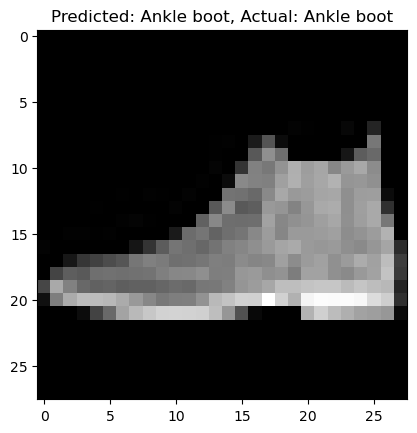

In [49]:
# Make predictions on the test set
predictions = model.predict(test_images)

# Display the predicted class for the first test image
predicted_class = np.argmax(predictions[0])
print(f"Predicted Class: {class_names[predicted_class]}")
print(f"Actual Class: {class_names[test_labels[0]]}")

# Visualize the first test image
plt.figure()
plt.imshow(test_images[0].reshape(28, 28), cmap='gray')
plt.title(f"Predicted: {class_names[predicted_class]}, Actual: {class_names[test_labels[0]]}")
plt.show()

#### **Explanation:**
- The model makes predictions on the test set using the `predict()` function.
- The predicted class for the first test image is displayed, along with the actual class.
- The first test image is visualized to verify the prediction.

### Loss and Validation Plots

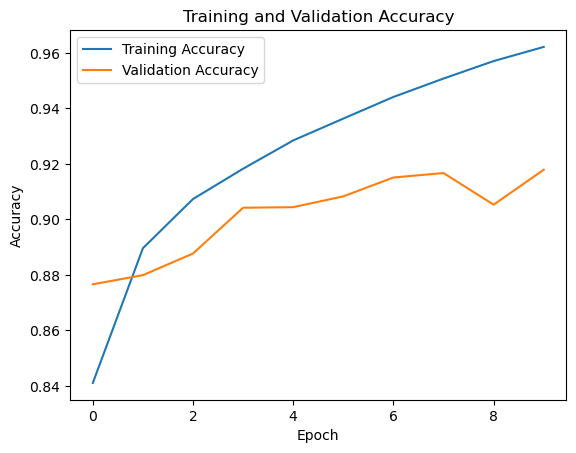

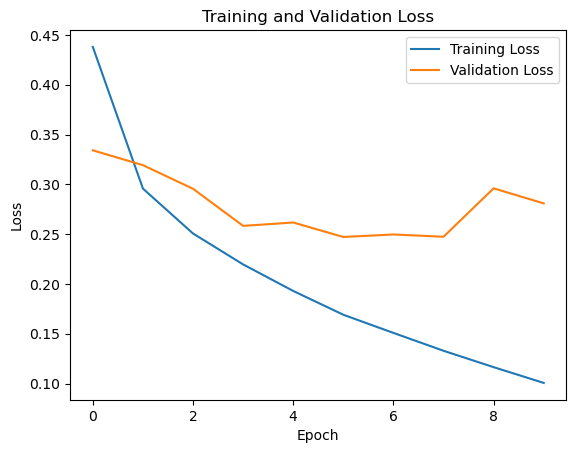

In [50]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

#### **Explanation:**
- The training and validation accuracy are plotted over the epochs to visualize the model's learning progress.
- The training and validation loss are also plotted to check for overfitting or underfitting.

### Test our model with an image from dataset 

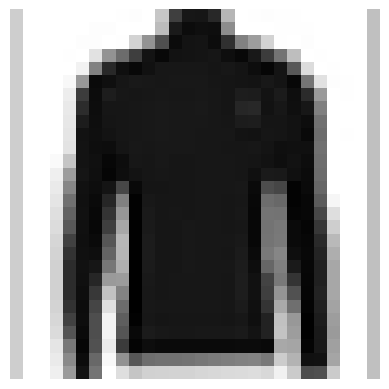

1/1 [==============================] - 0s 14ms/step
Predicted class: 2
 Pullover
Confidence: 0.99292374


In [53]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load and preprocess the image
image_path = "phototest.jpg"
image = Image.open(image_path).convert('L')  # Convert to grayscale
image = image.resize((28, 28))  # Resize to match the input size of the model
image = np.array(image)  # Convert to numpy array
image = image.reshape((1, 28, 28, 1)).astype('float32') / 255  # Reshape and normalize

# Display the image
plt.imshow(image.reshape(28, 28), cmap='gray')
plt.axis('off')
plt.show()


# Make predictions
predictions = model.predict(image)

# Interpret the results
predicted_class = np.argmax(predictions)
confidence = np.max(predictions)

# Print the predicted class and confidence
print("Predicted class:", predicted_class)
print(f" {class_names[predicted_class]}")
# Display the predicted class for the first test image

print("Confidence:", confidence)


In [56]:
print(predictions)

[[5.4000649e-03 1.0458738e-08 9.9292374e-01 1.4789149e-09 4.4898782e-10
  3.4931244e-12 2.9429232e-04 4.9623751e-15 1.3818707e-03 1.3969678e-12]]
